**Table of contents**<a id='toc0_'></a>    
- 1. [包](#toc1_)    
- 2. [向量](#toc2_)    
- 3. [线性变换](#toc3_)    
  - 3.1. [矩阵](#toc3_1_)    
- 4. [特征值和特征向量](#toc4_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# 1. <a id='toc1_'></a>[包](#toc0_)

In [7]:
import numpy as np
from matplotlib import pyplot as plt 
import seaborn as sns 


sns.set_theme(
    context='paper', style='ticks', palette='husl', font='Arial',
    rc = {
        'svg.fonttype': 'none',
        'pdf.fonttype': 42, 
        'ps.fonttype': 42, 
        'axes.titlesize': 8,
        'axes.labelsize': 8,
        'xtick.labelsize': 7,
        'ytick.labelsize': 7,
        'legend.fontsize': 6,
        'figure.constrained_layout.use': True,
    }
)

# 2. <a id='toc2_'></a>[向量](#toc0_)

# 3. <a id='toc3_'></a>[线性变换](#toc0_)

什么是线性关系？满足以下两种特性的关系：
- 可加性: $f(x_1 + x_2) = f(x_1) + f(x_2)$, 组合的函数等于函数的组合；
- 比例性: $f(kx) = k*f(x)$, 组合的比例等于函数的比例。

哪些操作属于线性变换？凡是将直线映射后仍然是直线（不弯曲）的操作：
- 旋转：将每个向量绕原点旋转一个固定角度。
- 缩放：沿坐标轴方向拉伸或压缩。
- 剪切：将向量沿某方向推移。
- 投影：将向量投射到某个子空间上。
- 反射：关于某条直线或平面的镜像。

这些操作的共同特点是：原点不动 $(T(0)=0)$，且直线映射后仍然是直线（不弯曲）。

## 3.1. <a id='toc3_1_'></a>[矩阵](#toc0_)

矩阵其实就是一种线性变换 (线性映射)。矩阵乘法本身天然是线性的：对于任意矩阵 $A$，向量 $u,v$ 和标量 $c$，$A(u+v)=Au+Av, A(cv)=cAv$, 因此，映射 $x↦Ax$ 一定是一个线性变换。

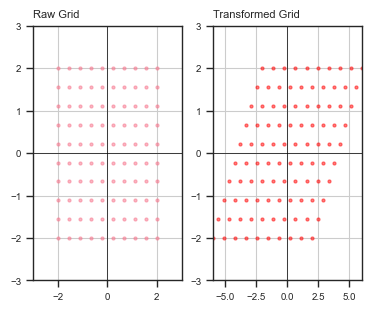

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 定义变换矩阵：x方向拉伸2倍，y方向不变，再加剪切
A = np.array([[2, 1],
              [0, 1]])

# 生成原始网格点
x = np.linspace(-2, 2, 10)
y = np.linspace(-2, 2, 10)
X, Y = np.meshgrid(x, y)
points = np.vstack([X.ravel(), Y.ravel()])

# 应用变换
transformed = A @ points

# 绘图
fig, axes = plt.subplots(1, 2, layout='constrained', figsize=(3*1.2, 3))

axes[0].scatter(points[0, :], points[1, :], s=5, alpha=0.5)
axes[0].set_title('Raw Grid', loc='left')
axes[0].set_xlim(-3, 3)
axes[0].set_ylim(-3, 3)
axes[0].axhline(0, color='k', linewidth=0.5)
axes[0].axvline(0, color='k', linewidth=0.5)
axes[0].grid(True)

axes[1].scatter(transformed[0, :], transformed[1, :], s=5, alpha=0.5, c='red')
axes[1].set_title('Transformed Grid', loc='left')
axes[1].set_xlim(-6, 6)
axes[1].set_ylim(-3, 3)
axes[1].axhline(0, color='k', linewidth=0.5)
axes[1].axvline(0, color='k', linewidth=0.5)
axes[1].grid(True)

# 4. <a id='toc4_'></a>[特征值和特征向量](#toc0_)

通俗理解: 存在一个 向量, 用一个线性变换（比如拉伸、旋转、剪切）去作用它, 这个向量变化后只是缩放了一定 $λ$ 倍数, 而方向不变。

数学定义: 设 $A$ 是一个 $n×n$ 的方阵（代表一个线性变换）。如果存在一个非零向量  $v$ 和一个标量 $λ$，使得: $Av = λv$, 那么 $v$ 称为 $A$ 的特征向量，$λ$ 称为对应的特征值。

解读:
- 左边 $Av$ 是变换后的向量。
- 右边 $λv$ 是原向量 $v$ 的缩放。
- 等式表明：经过变换后，$v$ 方向不变（或相反），只被拉伸或压缩了 $λ$ 倍。

求解: 计算	解 $det(A−λI)=0$ 求 $λ$，再解 $(A−λI)v=0$ 求 $v$